# EDA: `suburbs_final.csv`

Exploratory analysis of the merged suburb table (**680** suburbs) from `scraped_data/suburbs_final.csv`.

Built by `pre-processing.ipynb` (merge cell) or `rebuild_suburbs_final.py`.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_project_root() -> Path:
    """Nearest ancestor (or cwd) holding scraped_data/ -- works from the project root or eda/."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "scraped_data").is_dir():
            return folder
    raise FileNotFoundError(
        f"Could not find scraped_data/ starting from {here}. "
        "Open Jupyter with the project folder as the working directory."
    )


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
# gp_data_status separates "no doctors here" from "we never scraped this suburb".
from gp_supply import rankable_mask, require_status_column, status_summary

DATA_PATH = ROOT / "scraped_data" / "suburbs_final.csv"
df = pd.read_csv(DATA_PATH)
require_status_column(df, DATA_PATH)

assert len(df) == 680, f"Expected 680 suburbs, got {len(df)} - re-run the merge or rebuild script."
print(f"Loaded {len(df)} rows from {DATA_PATH.resolve()}")
print("GP data status:")
print(status_summary(df))
print(
    "\nOnly 'ok' rows carry observed GP supply. On a 'no_data' or 'gp_count_unknown' row,\n"
    "total_gp == 0 means the supply was never measured - NOT that there are no doctors.\n"
    "Filter with rankable_mask(df) before ranking anything on supply."
)
df.head(10)


In [ ]:
df.info()
df.describe().T

In [ ]:
# --- Null / NaN / empty / "missing" audit ---

# 1) Standard NaN (how pandas reads the CSV)
na_per_col = df.isna().sum()
print("=== NaN count per column ===")
print(na_per_col.to_string())
print(f"\nTotal NaN cells: {int(na_per_col.sum())}")

row_any_na = df.isna().any(axis=1)
print(f"Rows with any NaN: {row_any_na.sum()}")
if row_any_na.any():
    display(df.loc[row_any_na].sort_values("suburb"))

# 2) Empty or whitespace-only strings (if any column read as object)
print("\n=== Empty / whitespace-only (per column) ===")
obj_cols = df.select_dtypes(include=["object"]).columns
for c in obj_cols:
    s = df[c].astype(str)
    empty = s.str.strip().isin(["", "nan", "None", "NaN", "null"])
    n = int(empty.sum())
    if n:
        print(f"  {c}: {n}")

# 3) Duplicate suburb names (should be 0)
dup = df["suburb"].duplicated(keep=False) if "suburb" in df.columns else pd.Series(False, index=df.index)
print(f"\n=== Duplicate suburb rows: {dup.sum()} ===")
if dup.any():
    display(df.loc[dup].sort_values("suburb"))

# 4) Optional: treat 0 as "missing" for income fields (common scrape quirk)
inc_cols = [
    "median_household_income_weekly",
    "median_family_income_weekly",
    "median_personal_income_weekly",
]
present_inc = [c for c in inc_cols if c in df.columns]
if present_inc:
    z = df[present_inc].apply(pd.to_numeric, errors="coerce").eq(0)
    print(f"\n=== Rows with any median income == 0 (possible missing): {z.any(axis=1).sum()} ===")

In [ ]:
pop = pd.to_numeric(df["population"], errors="coerce")
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pop.dropna(), bins=40, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(pop.median(), color="darkred", linestyle="--", label=f"Median: {pop.median():,.0f}")
ax.set_xlabel("Population")
ax.set_ylabel("Number of suburbs")
ax.set_title("Distribution of suburb population")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
# total_gp == 0 is evidence of "no doctors" ONLY where gp_data_status == "ok".
# The naive count is the original bug: it lumps the 239 never-scraped suburbs and the 8
# whose clinic counts were all blank in with the genuinely empty ones.
rankable = rankable_mask(df)
verified_zero = int((rankable & (df["total_gp"] == 0)).sum())
unmeasured = int((~rankable).sum())
naive = int((df["total_gp"] == 0).sum())

print(f"VERIFIED zero GP count (status 'ok'):  {verified_zero:3d} ({100 * verified_zero / len(df):.1f}%)")
print(f"Supply never measured (not rankable):  {unmeasured:3d} ({100 * unmeasured / len(df):.1f}%)")
print(f"Naive 'total_gp == 0' count:           {naive:3d} ({100 * naive / len(df):.1f}%)  <- misleading, do not quote")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df.loc[rankable, "total_gp"], bins=50, color="seagreen", edgecolor="white", alpha=0.85)
ax.set_xlabel("total_gp (suburbs with measured supply only)")
ax.set_ylabel("Count")
ax.set_title(f"Distribution of GP counts - {int(rankable.sum())} suburbs with observed supply")
fig.tight_layout()
plt.show()


In [ ]:
inc_cols = [
    "median_household_income_weekly",
    "median_family_income_weekly",
    "median_personal_income_weekly",
]
zero_mask = (df[inc_cols] == 0).any(axis=1)
print(f"Suburbs with any median income == 0: {zero_mask.sum()}")
df.loc[zero_mask, ["suburb"] + inc_cols].sort_values("suburb")

In [ ]:
small = df[pd.to_numeric(df["population"], errors="coerce") < 1000].sort_values("population")
print(f"Population < 1,000: {len(small)} suburbs")
# gp_data_status shown so a 0 here is not misread as an absence of doctors.
small[["suburb", "population", "total_gp", "gp_data_status"]].head(20)


In [3]:
# Median personal weekly income > median household weekly income
# (unusual at suburb level - often indicates very small populations / data quirks)

from pathlib import Path

import pandas as pd

# Works even if you run this cell alone (kernel restart / out of order)
if "df" not in globals():
    df = pd.read_csv(Path("scraped_data") / "suburbs_final.csv")

h = "median_household_income_weekly"
p = "median_personal_income_weekly"

work = df.copy()
work[h] = pd.to_numeric(work[h], errors="coerce")
work[p] = pd.to_numeric(work[p], errors="coerce")

cmp = work.dropna(subset=[h, p])
personal_gt_household = cmp[cmp[p] > cmp[h]].sort_values(p, ascending=False)

print(f"Suburbs where {p} > {h}: {len(personal_gt_household)}")
personal_gt_household[["suburb", h, p]].assign(
    diff_personal_minus_household=personal_gt_household[p] - personal_gt_household[h]
)

Suburbs where median_personal_income_weekly > median_household_income_weekly: 1


,suburb,median_household_income_weekly,median_personal_income_weekly,diff_personal_minus_household
308,Huntingwood,0,1900,1900


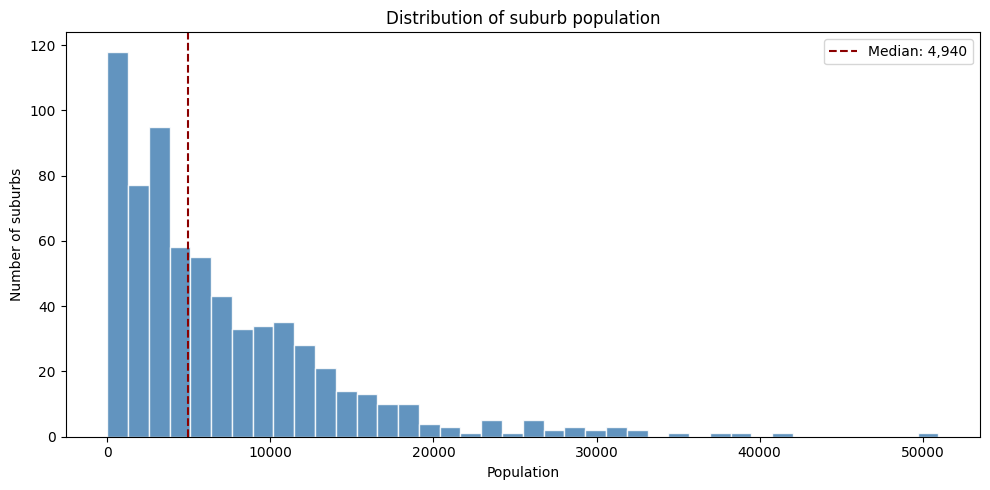

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(Path("scraped_data") / "suburbs_final.csv")
pop = pd.to_numeric(df["population"], errors="coerce").dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pop, bins=40, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(pop.median(), color="darkred", linestyle="--", linewidth=1.5, label=f"Median: {pop.median():,.0f}")
ax.set_xlabel("Population")
ax.set_ylabel("Number of suburbs")
ax.set_title("Distribution of suburb population")
ax.legend()
fig.tight_layout()
plt.show()

C:\Users\nhu92\AppData\Local\Temp\ipykernel_6240\1809389444.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(pop, vert=True, labels=["Population"])


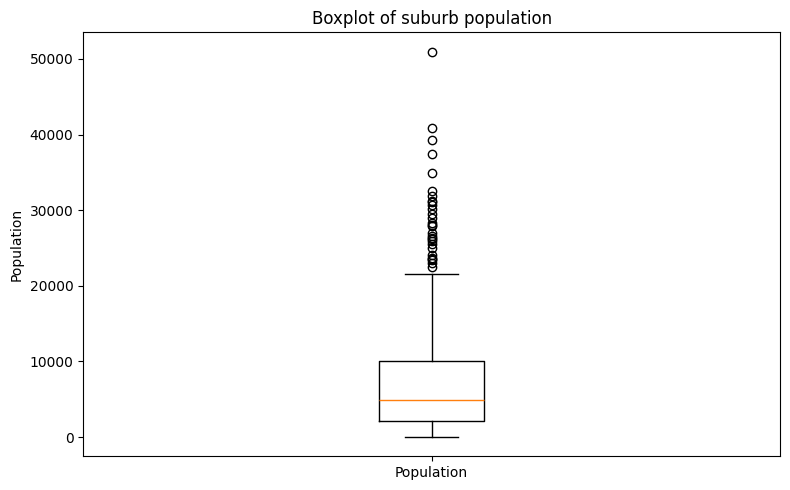

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(Path("scraped_data") / "suburbs_final.csv")
pop = pd.to_numeric(df["population"], errors="coerce").dropna()

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(pop, vert=True, labels=["Population"])
ax.set_ylabel("Population")
ax.set_title("Boxplot of suburb population")
fig.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

import pandas as pd

# Load (or use existing df from an earlier cell)
df = pd.read_csv(Path("scraped_data") / "suburbs_final.csv")

# 1) NaN
na_per_col = df.isna().sum()
print("NaN per column:\n", na_per_col.to_string())
print("Total NaN cells:", int(na_per_col.sum()))

row_any_na = df.isna().any(axis=1)
print("Rows with any NaN:", int(row_any_na.sum()))
if row_any_na.any():
    print(df.loc[row_any_na].sort_values("suburb").to_string(index=False))

# 2) Empty / whitespace in text columns
print("\nEmpty / whitespace-only counts:")
for c in df.select_dtypes(include=["object"]).columns:
    s = df[c].astype(str)
    n = int(s.str.strip().isin(["", "nan", "None", "NaN", "null"]).sum())
    if n:
        print(f"  {c}: {n}")

# 3) Duplicate suburbs
d = df["suburb"].duplicated(keep=False)
print("\nDuplicate suburb rows:", int(d.sum()))
if d.any():
    print(df.loc[d].sort_values("suburb").to_string(index=False))

# 4) Zero incomes (optional “missing” flag)
inc = [
    "median_household_income_weekly",
    "median_family_income_weekly",
    "median_personal_income_weekly",
]
inc = [c for c in inc if c in df.columns]
if inc:
    z = df[inc].apply(pd.to_numeric, errors="coerce").eq(0).any(axis=1)
    print("\nRows with any median income == 0:", int(z.sum()))

NaN per column:
 suburb                            0
total_gp                          0
area                              0
population                        0
over_65_pct                       0
median_household_income_weekly    0
median_family_income_weekly       0
median_personal_income_weekly     0
Total NaN cells: 0
Rows with any NaN: 0

Empty / whitespace-only counts:

Duplicate suburb rows: 0

Rows with any median income == 0: 4


C:\Users\nhu92\AppData\Local\Temp\ipykernel_6240\2477373723.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include=["object"]).columns:


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path


def find_eda_data_csv() -> Path:
    """Find scraped_data/eda_data.csv from cwd or any parent (works if cwd is eda/)."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        cand = folder / "scraped_data" / "eda_data.csv"
        if cand.is_file():
            return cand
    raise FileNotFoundError(
        "Could not find scraped_data/eda_data.csv starting from "
        f"{here}. Open Jupyter with the project folder as working directory."
    )


data_path = find_eda_data_csv()
print("Using:", data_path)
df = pd.read_csv(data_path)
require_status_column(df, data_path)
for c in [
    "total_gp",
    "population",
    "over_65_pct",
    "spatial_density",
    "median_household_income_weekly",
]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")
df["total_gp"] = df["total_gp"].fillna(0).clip(lower=0)
# GPs per 1,000 is only defined where supply was actually measured. Computing it for
# never-scraped suburbs yields 0.0, which reads as the worst possible access and put
# unscraped suburbs at the top of all three tables below.
_rankable = rankable_mask(df)
df["gp_per_1000"] = np.where(
    _rankable & (df["population"] > 0),
    1000.0 * df["total_gp"] / df["population"],
    np.nan,
)


def zscore(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    m, sd = s.mean(), s.std(ddof=0)
    if sd == 0 or np.isnan(sd):
        return s * 0.0
    return (s - m) / sd


MIN_POP = 1000
# Cohort = big enough for stable rates AND supply actually observed.
_cohort = (df["population"] >= MIN_POP) & _rankable
_held_out = int(((df["population"] >= MIN_POP) & ~_rankable).sum())
r = df[_cohort].copy()
print(
    f"Ranking cohort: {len(r)} suburbs (population >= {MIN_POP}, gp_data_status == 'ok').\n"
    f"Held out: {_held_out} suburbs of that size with no measured GP supply - they are\n"
    "re-scrape candidates, not low-opportunity suburbs. See eda/excluded_no_gp_data.csv."
)
r["z_pop"] = zscore(r["population"])
r["z_65"] = zscore(r["over_65_pct"])
r["z_den"] = zscore(r["spatial_density"])
# Every cohort row is rankable, so gp_per_1000 is non-null here; the old .fillna(0)
# would silently reintroduce a fake "zero access" if that ever stopped holding.
assert r["gp_per_1000"].notna().all(), "unmeasured suburb leaked into the ranking cohort"
r["z_gp"] = zscore(r["gp_per_1000"])
r["sig_pop_lowgp"] = r["z_pop"] - r["z_gp"]
r["sig_65_lowgp"] = r["z_65"] - r["z_gp"]
r["sig_density_lowgp"] = r["z_den"] - r["z_gp"]

print(f"\n=== 1) High population, low GP (pop >= {MIN_POP}) ===")
print(
    r.nlargest(15, "sig_pop_lowgp")[
        ["suburb", "population", "total_gp", "gp_per_1000", "total_gp_is_floor", "sig_pop_lowgp"]
    ].to_string(index=False)
)
print(f"\n=== 2) High share aged 65+, low GP (pop >= {MIN_POP}) ===")
print(
    r.nlargest(15, "sig_65_lowgp")[
        ["suburb", "over_65_pct", "population", "total_gp", "gp_per_1000", "sig_65_lowgp"]
    ].to_string(index=False)
)
print(f"\n=== 3) High spatial density, low GP (pop >= {MIN_POP}) ===")
print(
    r.nlargest(15, "sig_density_lowgp")[
        ["suburb", "spatial_density", "population", "total_gp", "gp_per_1000", "sig_density_lowgp"]
    ].to_string(index=False)
)
print(
    "\nAll rows above have observed GP supply (gp_data_status == 'ok').\n"
    "total_gp_is_floor=True means at least one clinic reported no usable doctor count,\n"
    "so that suburb's real supply is higher and its apparent shortage is overstated."
)

